# Getting started with PID Prover

This notebook tours the analyses of the package: the properties of each PID measure (Table 5 of the paper), the theorems relating them, and what the Z3 prover can derive from them.

Install with `pip install -e ".[notebooks]"` from the repository root.

In [1]:
from pid_prover import (
    THEOREMS, explain_assignment, find_maximal_compatible_sets, find_minimal_conflicts,
    find_minimal_implications, infer_property_consequences, is_consistent,
    measure_properties, measures_df, redundant_theorems, validate_measures,
)

## 1. Measures and their properties

`measures_df` is Table 5, with the same symbols as the paper (✓†: only for n = 2 sources, n.a.: measure only defined for n = 2, etc.).

In [2]:
measures_df

,I_min,I_MMI,I_RDR,I_BROJA,I_delta,I_red,I_IG,I_RR,I_DEP,I_CT,I_RAV,I_wedge,I_alpha,I_prec,I_MES,I_do,I_PM,I_SX,I_CCS
SR,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓
S0,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓
M0,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓†,✓,✓,✓,✗,✗,✗‡,✗‡,✗
GP,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,✓,✗‡,✗‡,✗
LP0,✓,✓,✓,✓,✓,✓,✓,✓,✓,✗,✓,✗,✗,✗,✗,✗,✗‡,✗‡,✗
LP1,✓,✓,✓,n.a.,n.a.,n.a.,n.a.,n.a.,n.a.,✗,✗,✗,✗,✗,n.a.,n.a.,✗‡,✗‡,✗
IID,✗,✗,✗,✓,✓,✓,✗,✓,✓,✓,✓,✓,✓,✓,✓,✓,✗,✗,✓
ID,✗,✗,✗,✓,✓,✓,✗,✗,✓,✓,✓,✗,✗,✗,✓,✓,✗,✗,✗
TM,✗,✓,✗,✗,✗,✗,✓*,✗,✗,✓,✗,✓,✗,✗,✗,✗,✗,✗,✗
TC,✗,✗,✗,✗,✗,✗,✗,✗,✗,✗,✗,✗,✗,✗,✗,✗,✓,✓,✗


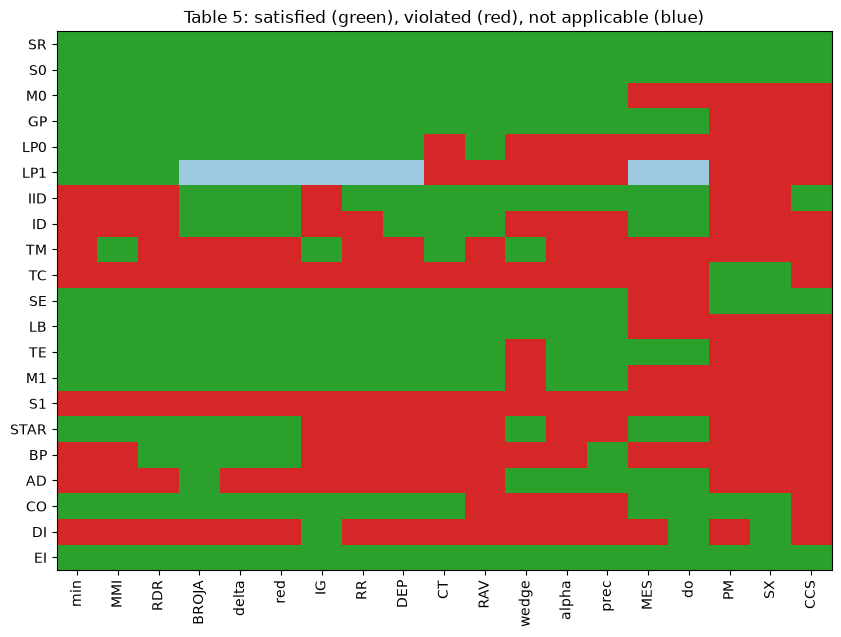

In [3]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

values = measures_df.apply(lambda col: col.map(lambda e: 0.5 if e == "n.a." else float(e.startswith("✓"))))
fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(values, cmap=ListedColormap(["#d62728", "#9ecae1", "#2ca02c"]), aspect="auto")
ax.set_xticks(range(values.shape[1]), [m.removeprefix("I_") for m in values.columns], rotation=90)
ax.set_yticks(range(values.shape[0]), values.index)
ax.set_title("Table 5: satisfied (green), violated (red), not applicable (blue)")
plt.show()

## 2. Validating Table 5

Each measure's ✓ entries are set to true and its ✗ entries to false, and the assignment is checked against all theorems, in the bivariate case (n = 2) and in the multivariate case (any n).

In [4]:
validate_measures()


Case: bivariate (n = 2)
  I_min      PASS
  I_MMI      PASS
  I_RDR      PASS
  I_BROJA    PASS
  I_delta    PASS
  I_red      PASS
  I_IG       PASS
  I_RR       PASS
  I_DEP      PASS
  I_CT       PASS
  I_RAV      PASS
  I_wedge    PASS
  I_alpha    PASS
  I_prec     PASS
  I_MES      PASS
  I_do       PASS
  I_PM       PASS
  I_SX       PASS
  I_CCS      PASS

Case: multivariate (any n)
  I_min      PASS
  I_MMI      PASS
  I_RDR      PASS
  I_BROJA    skipped (only defined for n = 2)
  I_delta    skipped (only defined for n = 2)
  I_red      skipped (only defined for n = 2)
  I_IG       skipped (only defined for n = 2)
  I_RR       skipped (only defined for n = 2)
  I_DEP      skipped (only defined for n = 2)
  I_CT       PASS
  I_RAV      PASS
  I_wedge    PASS
  I_alpha    PASS
  I_prec     PASS
  I_MES      skipped (only defined for n = 2)
  I_do       skipped (only defined for n = 2)
  I_PM       PASS
  I_SX       PASS
  I_CCS      PASS

All measures are consistent with the t

True

When an assignment is inconsistent, `explain_assignment` returns a minimal set of contradictory entries. For instance, a hypothetical measure satisfying (M<sub>0</sub>) and (SR) but violating (LB) would contradict Prop. 1:

In [5]:
entries = {p: v for p, v in [("SR", True), ("M0", True), ("LB", False), ("AD", True)]}
explain_assignment(entries)

['SR', 'M0', '¬LB']

## 3. The encoded theorems

In [6]:
for t in THEOREMS:
    print(f"{t.name:<9} {t.statement()}" + ("" if t.case == "all" else f"  [{t.case}]"))
print("\nFollow from the other results:", redundant_theorems("multivariate"))

Lemma 1   (LP) ⇒ (GP)
Lemma 2   (ID) ⇒ (IID)
Lemma 3   (S1) ⇒ (S0)
Lemma 4   (M0) ⇒ (SE)
Lemma 5   (DI) ⇒ (CO)
Prop. 1   (M0), (SR) ⇒ (LB)
Prop. 2   (SR), (LB) ⇒ (GP)
Prop. 3   (M0), (SR) ⇒ (GP)
Prop. 4   (S0), (LP) ⇒ (M0)
Prop. 5   (GP), (TC) ⇒ (TM)
Prop. 6   (SR), (S0), (LP) ⇒ (TE)
Prop. 7   (SR), (S0), (LP) ⇒ (M1)
Theo. 1   (S0), (SR), (EI), (LP1), (IID) are incompatible  [multivariate]
Theo. 2   (SR), (S0), (M0), (TC) are incompatible
Cor. 1    (SR), (S0), (LP), (TC) are incompatible
Cor. 2    (SR), (S0), (EI), (LP), (IID), (TC) are incompatible
Theo. 3   (SR), (S0), (TC), (TE) ⇒ (ID)
Cor. 3    (SR), (S0), (LP), (TC) ⇒ (ID)
Theo. 4   (M0), (TE) ⇔ (M1)
Theo. 5   (BP) ⇒ (SE), (TE)  [bivariate]
Theo. 7   (M0), (S1) ⇒ (TM)
Theo. 8   (SE), (S1) ⇒ (TE)
Theo. 9   (SR), (SE), (S1) ⇒ (ID)
Theo. 10  (M0), (SR), (LP1), (S1) are incompatible  [multivariate]

Follow from the other results: ['Prop. 3', 'Prop. 7', 'Cor. 1', 'Cor. 2', 'Cor. 3']


## 4. No-go theorems

Minimal sets of incompatible properties. For n = 2, only Theo. 2 and its consequence Cor. 1 remain; for any n, the prover also finds consequences of combining the results, such as the incompatibility of (SR), (LP) and (S<sub>1</sub>).

In [7]:
for n in ["bivariate", "multivariate"]:
    print(n)
    for conflict in find_minimal_conflicts(n, max_size=6):
        print("  {" + ", ".join(conflict) + "}")

bivariate


  {SR, S0, TC, M0}
  {SR, S0, TC, LP}
multivariate


  {SR, LP, S1}
  {SR, S0, TC, M0}
  {SR, S0, TC, LP}
  {SR, S0, IID, EI, LP}


## 5. Implications

In [8]:
for premises, conclusion in find_minimal_implications("bivariate", premise_size=2):
    print(f"{' ∧ '.join(premises)} ⇒ {conclusion}")

SR ∧ M0 ⇒ GP
SR ∧ M0 ⇒ LB
SR ∧ LB ⇒ GP
SR ∧ M1 ⇒ GP
SR ∧ M1 ⇒ LB
S0 ∧ LP ⇒ M0
S0 ∧ LP ⇒ SE
M0 ∧ TE ⇒ M1
M0 ∧ S1 ⇒ TM
M0 ∧ S1 ⇒ TE
M0 ∧ S1 ⇒ M1
M0 ∧ BP ⇒ M1
GP ∧ TC ⇒ TM
LP ∧ TC ⇒ TM
LP ∧ S1 ⇒ M0
LP ∧ S1 ⇒ TM
LP ∧ S1 ⇒ SE
LP ∧ S1 ⇒ TE
LP ∧ S1 ⇒ M1
SE ∧ S1 ⇒ TE
M1 ∧ S1 ⇒ TM


## 6. Designing a measure

Which properties does a measure satisfying (SR), (S<sub>0</sub>) and (LP) necessarily satisfy or violate? (`LP` is shorthand for (LP<sub>0</sub>) and (LP<sub>1</sub>).)

In [9]:
infer_property_consequences(["SR", "S0", "LP"], "multivariate")

{'Consistent': True,
 'Mandatory': ['M0', 'GP', 'SE', 'LB', 'TE', 'M1'],
 'Forbidden': ['TC', 'S1']}

And which measures come closest to a maximal set of compatible properties? Below, all maximal sets (out of the 20 properties) that contain the Williams and Beer axioms (SR), (S<sub>0</sub>) and (M<sub>0</sub>), for any number of sources:

In [10]:
from pid_prover.properties import prop_names

maximal = find_maximal_compatible_sets("multivariate", required=["SR", "S0", "M0"])
for s in maximal:
    print(f"{len(s)} properties, all except {sorted(set(prop_names) - set(s))}")

18 properties, all except ['LP', 'TC']
17 properties, all except ['EI', 'S1', 'TC']
16 properties, all except ['ID', 'IID', 'S1', 'TC']


Dropping (M<sub>0</sub>) instead, while keeping (SR) and (S<sub>0</sub>), forces abandoning (LP) (Prop. 4) and (M<sub>1</sub>) (Theo. 4), but makes the Target Chain rule (TC) admissible:

In [11]:
for s in find_maximal_compatible_sets("multivariate", required=["SR", "S0"], excluded=["M0"]):
    print(f"{len(s)} properties, all except {sorted(set(prop_names) - set(s))}")

17 properties, all except ['LP', 'M0', 'M1']


In [12]:
for measure in ["I_min", "I_MMI", "I_RDR", "I_CT"]:
    props = set(measure_properties(measure, "multivariate"))
    best = max((s for s in maximal if props <= set(s)), key=len, default=None)
    missing = sorted(set(best) - props) if best else "not contained in any of these sets"
    print(f"{measure}: {len(props)} properties, missing {missing}")

I_min: 12 properties, missing ['AD', 'BP', 'DI', 'TM']
I_MMI: 13 properties, missing ['AD', 'BP', 'DI']
I_RDR: 13 properties, missing ['AD', 'DI', 'TM']
I_CT: 13 properties, missing ['AD', 'BP', 'DI', 'S1', 'STAR']
